In [1]:
%load_ext jupyter_black
%matplotlib inline

import os
# Set cuda device to use
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

# do not prealocate memory when using jax
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"

In [2]:
from multipledispatch import dispatch
from typing import NamedTuple
from jaxtyping import Array

import jax.numpy as jnp
import jax.random as jr
import numpyro.distributions as dist

from jax import nn
from jax.scipy.special import digamma, gammaln, logsumexp
from jax.scipy import linalg

from jax import vmap
import matplotlib.pyplot as plt

In [3]:
import numpy as np
from local import MABTask, UCBAgent
from pybefit.agents import transform


from pybefit.inference import NumpyroGuide as Guide
from pybefit.inference import NumpyroModel as Model
from numpyro.infer import Predictive
import numpyro.distributions as dist
from pybefit.inference.numpyro.likelihoods import befit_likelihood as likelihood
from pybefit.inference.methods import (
    default_dict_numpyro_svi,
    format_posterior_samples,
    get_log_evidence_per_subject,
)

default_dict_svi = default_dict_numpyro_svi

from pybefit.inference import MultivariateNormal as Prior
from pybefit.inference import NormalPosterior as Posterior

from pybefit.inference import run_svi

In [4]:
class MVNIW(NamedTuple):
    """Multivariate Normal Inverse Wishart distribution

    loc: mean of the multivariate normal distribution
    kappa: precision multiplier scalar
    wish: wishart distribution
    """

    loc: Array
    kappa: float
    wish: dist.WishartCholesky


def multivariate_digamma(x, d):
    return digamma(jnp.expand_dims(x, -1) + (1 - jnp.arange(1, d + 1)) / 2).sum(-1)


def multivariate_gammaln(x, d):
    c = d * (d - 1) / 4 * jnp.log(jnp.pi)
    return gammaln(jnp.expand_dims(x, -1) + (1 - jnp.arange(1, d + 1)) / 2).sum(-1) + c


@dispatch(dist.WishartCholesky, dist.WishartCholesky)
def kl_divergence(p, q):
    n0 = p.concentration / 2
    n1 = q.concentration / 2
    d = p.event_shape[-1]

    assert d == q.event_shape[-1]

    kl_div = (n0 - n1) * multivariate_digamma(n0, d)
    kl_div += n1 * jnp.log(jnp.diagonal(p.scale_tril, axis1=-1, axis2=-2)).sum(-1)
    kl_div -= n1 * jnp.log(jnp.diagonal(q.scale_tril, axis1=-1, axis2=-2)).sum(-1)
    kl_div += n0 * (jnp.trace(q.scale_matrix @ p.rate_matrix, axis1=-1, axis2=-2) - d)
    kl_div += multivariate_gammaln(n1, d) - multivariate_gammaln(n0, d)

    return kl_div


@dispatch(MVNIW, MVNIW)
def kl_divergence(p, q):
    d = p.loc.shape[-1]
    kappa_p = p.kappa
    kappa_q = q.kappa
    P = jnp.expand_dims(p.wish.concentration * kappa_q, (-1, -2)) * p.wish.rate_matrix

    kl_div = d / 2 * (kappa_q / kappa_p + jnp.log(kappa_p) - jnp.log(kappa_q) - 1)
    diff = q.loc - p.loc
    kl_div += 0.5 * jnp.squeeze((P @ diff[..., None]).mT @ diff[..., None], (-1, -2))

    kl_div += kl_divergence(p.wish, q.wish)

    return kl_div


def betaln(alpha, beta):
    return gammaln(alpha) + gammaln(beta) - gammaln(alpha + beta)


@dispatch(dist.Beta, dist.Beta)
def kl_divergence(p, q):
    qa = q.concentration0
    qb = q.concentration1
    pa = p.concentration0
    pb = p.concentration1
    kl_div = betaln(qa, qb) - betaln(pa, pb)
    da = pa - qa
    kl_div += da * digamma(pa)
    db = pb - qb
    kl_div += db * digamma(pb)
    kl_div += (da + db) * digamma(pa + pb)
    return kl_div

In [5]:
def update_dp_params(qz, alpha=1.0):
    suma = qz.sum(0)
    gamma_1 = 1.0 + suma[:-1]  # shape: (K - 1,)
    gamma_2 = alpha + jnp.cumsum(suma[:0:-1])[::-1]  # shape: (K - 1,)
    return gamma_1, gamma_2


def update_mvniw(
    qx_z: dist.MultivariateNormal, qz: dist.Categorical, mvniw_prior: MVNIW
):
    probs = qz.probs
    exp_x_z = qx_z.mean
    exp_xz = jnp.expand_dims(probs, -1) * exp_x_z
    exp_xx_z = qx_z.covariance_matrix + exp_x_z[..., None] * exp_x_z[..., None, :]
    exp_xxz = jnp.expand_dims(probs, (-1, -2)) * exp_xx_z

    n_z = probs.sum(0)
    kappa_z = mvniw_prior.kappa + n_z
    loc_z = (
        mvniw_prior.loc
        + (exp_xz.sum(0) - n_z[..., None] * mvniw_prior.loc) / kappa_z[..., None]
    )

    ms_z = (mvniw_prior.kappa * mvniw_prior.loc) * mvniw_prior.loc[..., None]
    ms_z -= jnp.expand_dims(kappa_z[..., None] * loc_z, -2) * loc_z[..., None]
    V_z = mvniw_prior.wish.scale_matrix + ms_z + exp_xxz.sum(0)

    nu_z = mvniw_prior.wish.concentration + n_z

    wish = dist.WishartCholesky(nu_z, scale_matrix=V_z)

    return MVNIW(loc=loc_z, kappa=kappa_z, wish=wish)


def update_qz(log_likes, dp_params):
    """Update assignment probabilities (E-step)"""

    # Compute expected log stick-breaking terms
    e_ln_v = digamma(dp_params[0]) - digamma(dp_params[0] + dp_params[1])
    e_ln_1mv = digamma(dp_params[1]) - digamma(dp_params[0] + dp_params[1])

    # Compute cumulative sum of log(1-v) terms
    pad_width = [(0, 0)] * e_ln_1mv.ndim
    pad_width[-1] = (1, 0)
    cumsum_log_1mv = jnp.pad(e_ln_1mv, pad_width).cumsum(-1)

    # Compute log probabilities from stick-breaking process
    pad_width = [(0, 0)] * e_ln_v.ndim
    pad_width[-1] = (0, 1)
    log_pi = jnp.pad(e_ln_v, pad_width) + cumsum_log_1mv

    return log_pi + log_likes


def log_likelihood(y, mvniw_post):
    means = mvniw_post.loc
    kappa = mvniw_post.kappa
    nu = mvniw_post.wish.concentration
    P = jnp.expand_dims(nu, (-1, -2)) * mvniw_post.wish.rate_matrix

    N, D = y.shape
    K = means.shape[0]

    L = mvniw_post.wish.scale_tril
    const = -D * jnp.log(jnp.pi) / 2 - jnp.log(jnp.diagonal(L, axis1=-1, axis2=-2)).sum(
        -1
    )
    const += multivariate_digamma(nu / 2, D) / 2 - 0.5 * D / kappa

    y_cnt = jnp.expand_dims(y, -2) - means
    log_likes = -0.5 * jnp.squeeze(
        (P @ y_cnt[..., None]).mT @ y_cnt[..., None], (-1, -2)
    )

    return log_likes + const

In [6]:
def generate_dp_mixture_data(key, N=200, K=5, D=2):
    """Generate synthetic data from a DP mixture model"""
    # Generate true cluster parameters
    key1, key2, key3 = jr.split(key, 3)

    # Generate means
    means = jr.normal(key1, (K, D)) * 4

    # Generate assignments
    pi = jr.dirichlet(key2, jnp.ones(K))
    z = jr.categorical(key3, pi, shape=(N,))

    # Generate observations
    x = means[z] + jr.normal(key3, (N, D))

    return x, z, means


key = jr.PRNGKey(12345678910)
# Generate synthetic data
key, _key = jr.split(key)
N, K, D = 100, 3, 2
y, true_z, true_means = generate_dp_mixture_data(_key, N, K, D)

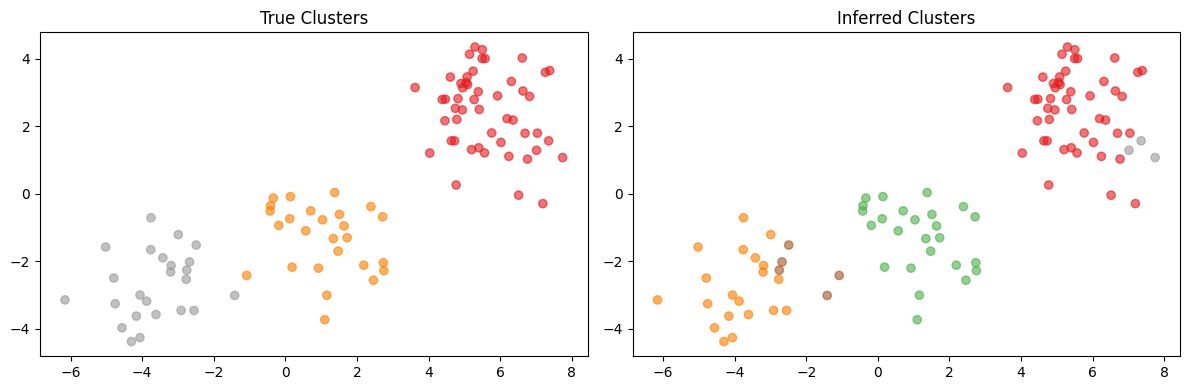

In [7]:
def cavi_update(key, y, mvniw_prior, num_iters=100, alpha=1.0, K_max=100):
    """Run variational inference updates for DPs"""
    N, D = y.shape
    K = K_max + 1

    beta0 = dist.Beta(alpha, 1.0)
    elbos = []
    u = jr.uniform(key, shape=(N, K))
    ln_qz = jnp.log(u / u.sum(-1, keepdims=True))
    for iter in range(num_iters):
        probs = jnp.exp(ln_qz)
        suma = probs.sum(0)
        args = jnp.argsort(suma)
        probs = probs[:, args[::-1]]
        if suma[-2:].sum() < 5 and iter > num_iters - K:
            probs = probs[..., :-1]

        qz = dist.Categorical(probs=probs)
        qx_z = dist.MultivariateNormal(
            loc=jnp.expand_dims(y, -2), scale_tril=jnp.eye(D) * 1e-12
        )
        mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
        dp_params = update_dp_params(qz.probs, alpha=alpha)

        log_likes = log_likelihood(y, mvniw_post)
        # Compute KL divergence for class params
        kl_div = kl_divergence(mvniw_post, mvniw_prior)
        log_likes -= kl_div

        ln_qz = update_qz(log_likes, dp_params)
        log_norm = logsumexp(ln_qz, -1, keepdims=True)
        ln_qz -= log_norm
        beta = dist.Beta(dp_params[1], dp_params[0])
        elbos.append(log_norm.sum() - kl_divergence(beta, beta0).sum())

    return qz, mvniw_post, dp_params, elbos


# Initialize variational parameters
mvniw_prior = MVNIW(
    loc=jnp.zeros(D), kappa=1 / 100, wish=dist.WishartCholesky(D + 2, jnp.eye(D))
)

K_max = 9
key, _key = jr.split(key)
qz, mvniw_post, dp_params, elbos = cavi_update(
    _key, y, mvniw_prior, num_iters=64, alpha=1, K_max=K_max
)

# Plot results
plt.figure(figsize=(12, 4))

plt.subplot(121)
plt.scatter(y[:, 0], y[:, 1], c=true_z, cmap="Set1", alpha=0.6)
plt.title("True Clusters")

plt.subplot(122)
plt.scatter(y[:, 0], y[:, 1], c=qz.probs.argmax(-1), cmap="Set1", alpha=0.6)
plt.title("Inferred Clusters")

plt.tight_layout()

In [8]:
blocks = 20
trials = 10
num_arms = 3
num_agents = 100
key = jr.PRNGKey(3447811)


def make_task(key, num_agents):
    # create task environment
    key, _key = jr.split(key)
    probs = jr.dirichlet(_key, jnp.ones(num_arms), shape=(num_agents,))
    key, _key = jr.split(key)
    outcomes = jr.binomial(key, 1, probs, shape=(blocks, trials, num_agents, num_arms))

    return MABTask(outcomes, backend="jax")


# create an agent to read out the number of parameters
ucb_agent = UCBAgent(
    runs=num_agents, blocks=blocks, trials=trials, num_arms=num_arms, backend="jax"
)

num_params = ucb_agent.num_params

# define a transform for mapping unconstrained parameters 'z' to the corresponding agent class
transform_ucb = lambda z, **kwargs: transform(z, UCBAgent, **kwargs)

# set kwargs for transform which are passed to the agent constractor
opts_transform = {
    "blocks": blocks,
    "trials": trials,
    "num_arms": num_arms,
    "backend": "jax",
}


# posterior = Guide(Posterior(num_params, num_agents, backend="numpyro"))
def make_model_and_sample(key, hyperparams, num_agents, return_model=False):
    key, _key = jr.split(key)
    mab_task = make_task(_key, num_agents)

    # set task and agent option dictionaries
    key, _key = jr.split(key)
    opts_task = {
        "task": mab_task,
        "num_blocks": blocks,
        "num_trials": trials,
        "num_agents": num_agents,
        "seed": _key[0],
    }

    # set options for prior, transform and likelihood
    opts_model = {"prior": {}, "transform": opts_transform, "likelihood": opts_task}

    prior = Prior(num_params, num_agents, hyperparams, backend="numpyro")
    gen_model = Model(prior, transform_ucb, likelihood, opts=opts_model)
    pred = Predictive(gen_model, num_samples=1)
    prior_predictive_sample = pred(key)

    ucb_agent.set_parameters(prior_predictive_sample["z"][0])
    true_vals = (ucb_agent.lr, ucb_agent.c, ucb_agent.beta)

    if return_model:
        return gen_model
    else:
        return prior_predictive_sample, true_vals


key, _key = jr.split(key)
P = dist.Wishart(
    num_params + 2,
    scale_tril=jnp.broadcast_to(
        jnp.eye(num_params) * 40 / (num_params + 2), (4, num_params, num_params)
    ),
).sample(_key)

L = jnp.linalg.cholesky(jnp.linalg.inv(P))
key, _key = jr.split(key)

v0 = jnp.array([-1.5, -0.5, 0, 0.5])
vals = []
for _ in range(num_params):
    key, _key = jr.split(key)
    vals.append(jr.permutation(_key, v0))
loc = jnp.stack(vals, -1)

loc -= jnp.array([2.0 / 4.0, 0.5, 1.5])

true_hyperparams = {"loc": loc, "scale_tril": L}

keys = jr.split(key, 4)
prior_predictive_sample, true_vals = vmap(make_model_and_sample, in_axes=(0, 0, None))(
    keys, true_hyperparams, num_agents // 4
)

lr 0.0018389769 c 0.25403902 beta 2.5017498
lr 0.093661085 c 0.4034844 beta 1.6084
lr 0.8665952 c 0.07975927 beta 0.34329218
lr 0.4938394 c 0.4933973 beta 0.78517723


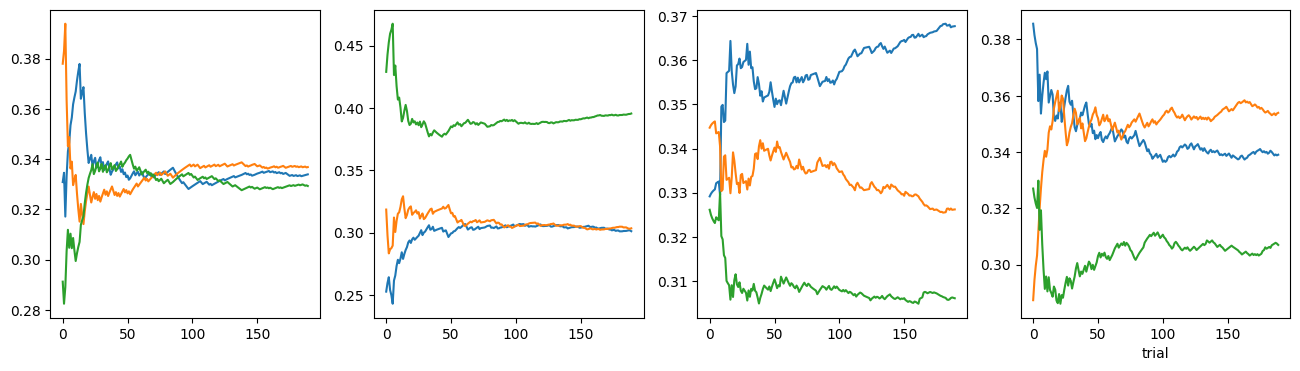

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
s = 0
for i in range(4):
    print("lr", true_vals[0][i, s], "c", true_vals[1][i, s], "beta", true_vals[2][i, s])
    logits = prior_predictive_sample["logits"][i, 0][1:, :, s, :].reshape(-1, num_arms)
    axes[i].plot(nn.softmax(logits, -1))

plt.xlabel("trial");

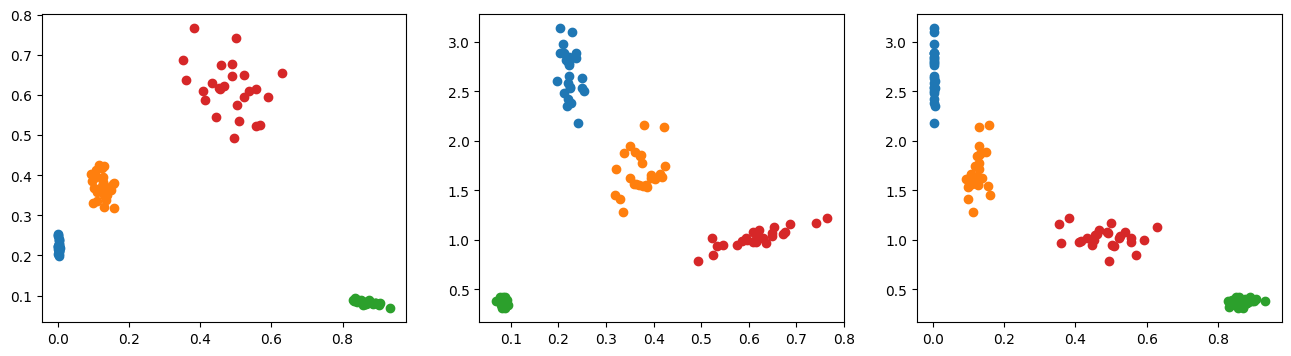

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i in range(4):
    axes[0].scatter(true_vals[0][i], true_vals[1][i])
    axes[1].scatter(true_vals[1][i], true_vals[2][i])
    axes[2].scatter(true_vals[0][i], true_vals[2][i])

In [11]:
def log_likelihood(key, data, hyperparams):
    measurments = {
        "offers": None,
        "outcomes": data["outcomes"],
        "mask": None,
        "responses": data["responses"],
    }

    # perform inference using stochastic variational inference
    opts_svi = default_dict_svi
    opts_svi.update(
        {
            "seed": key[0],
            "iter_steps": 10,
            "optim_kwargs": {"learning_rate": 0.01},
            "svi_kwargs": {"progress_bar": False, "stable_update": True},
        }
    )

    gen_model = make_model_and_sample(key, hyperparams, 1, return_model=True)
    posterior = Guide(Posterior(num_params, 1, backend="numpyro"))

    samples, svi, results = run_svi(gen_model, posterior, measurments, opts=opts_svi)

    return results


data = {
    "outcomes": jnp.moveaxis(prior_predictive_sample["outcomes"], 0, -2).reshape(
        blocks, trials, 1, -1
    ),
    "responses": np.moveaxis(prior_predictive_sample["responses"], 0, -2).reshape(
        blocks, trials, 1, -1
    ),
}


def get_marginal_ll(key, hyperparams, data):
    keys = jr.split(key, num_agents)
    results = vmap(log_likelihood, in_axes=(0, -1, None))(keys, data, hyperparams)
    return results


# results = get_marginal_ll(key, hyperparams, data)

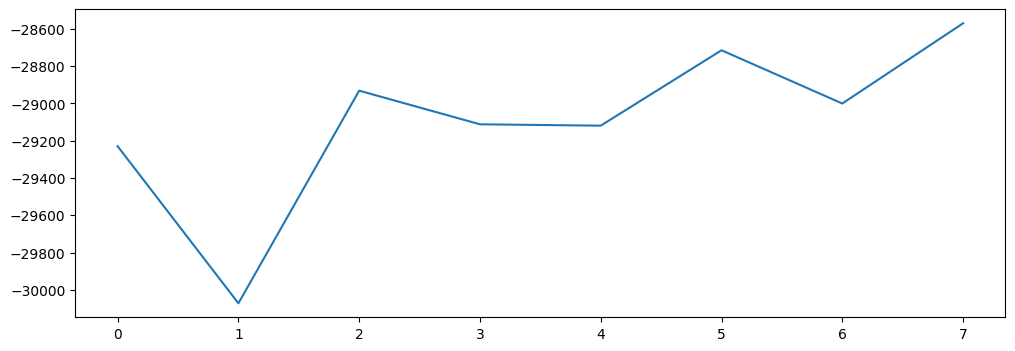

In [ ]:
alpha = 1
N = 100
K = 10
beta0 = dist.Beta(alpha, 1.0)

dp_params = (jnp.ones(K - 1), jnp.ones(K - 1) * alpha)

mvniw_prior = MVNIW(
    loc=jnp.zeros(num_params),
    kappa=1 / 10,
    wish=dist.WishartCholesky(
        num_params + 2, jnp.eye(num_params) * 10 / (num_params + 2)
    ),
)

key, _key = jr.split(key)
mvniw_post = MVNIW(
    loc=jr.normal(_key, shape=(K, num_params)) / jnp.sqrt(10 * mvniw_prior.kappa),
    kappa=1 / 10,
    wish=dist.WishartCholesky(
        num_params + 2, jnp.eye(num_params) * 10 / (num_params + 2)
    ),
)

elbos = []
for _ in range(8):
    nu = mvniw_post.wish.concentration
    P = jnp.broadcast_to(
        nu[..., None, None] * mvniw_post.wish.scale_matrix,
        (K, num_params, num_params),
    )
    hyperparams = {
        "loc": mvniw_post.loc,
        "precision_matrix": P,
    }

    # estimate posterior parameters with numpyro
    key, _key = jr.split(key)
    keys = jr.split(_key, K)
    results = vmap(get_marginal_ll, in_axes=(0, 0, None))(keys, hyperparams, data)

    log_likes = -results.losses[..., -20:].mean(-1).mT

    kl_div = kl_divergence(mvniw_post, mvniw_prior)
    log_likes -= kl_div

    residual = 0.5 * (
        multivariate_digamma(nu / 2, num_params)
        + num_params * jnp.log(2)
        - num_params / mvniw_post.kappa
        - jnp.log(nu)
    )
    log_likes += residual

    ln_qz = update_qz(log_likes, dp_params)
    log_norm = logsumexp(ln_qz, -1, keepdims=True)
    probs = jnp.exp(ln_qz - log_norm)
    suma = probs.sum(0)
    srt_idx = jnp.argsort(suma, -1)[::-1]
    qz = dist.Categorical(probs=probs[:, srt_idx])

    _loc = jnp.moveaxis(results.params["loc"].squeeze(-2), 0, 1)
    _sl = jnp.moveaxis(results.params["scale_tril"].squeeze(-3), 0, 1)
    qx_z = dist.MultivariateNormal(
        loc=_loc[:, srt_idx],
        scale_tril=_sl[:, srt_idx],
    )

    mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
    dp_params = update_dp_params(qz.probs, alpha=alpha)

    beta = dist.Beta(dp_params[1], dp_params[0])
    elbos.append(log_norm.sum() - kl_divergence(beta, beta0).sum())

plt.figure(figsize=(12, 4))
plt.plot(elbos)

<Axes: >

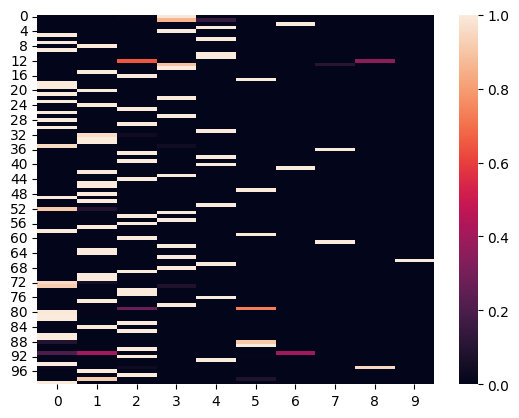

In [13]:
import seaborn as sns

sns.heatmap(qz.probs)

In the second variant we only fit the model once, and then just use BMR to refine the posterior and learn DP. 

TODO

In [25]:
hyperparams0 = {"loc": jnp.zeros(num_params), "scale_tril": 10 * jnp.eye(num_params)}
key, _key = jr.split(key)
results0 = get_marginal_ll(_key, hyperparams0, data)

K = N
probs = jnp.eye(N)

qz = dist.Categorical(probs=probs)

qx_z = dist.MultivariateNormal(
    loc=results0.params["loc"],
    scale_tril=results0.params["scale_tril"],
)

mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)
dp_params = update_dp_params(qz.probs, alpha=alpha)

In [ ]:
from jax.scipy.linalg import solve
def ΔF_mv(mu, P, mu1, P1, sigma_sqr=1.):
    # Delta F for multivariate normal prior-posterior
    P0 = jnp.eye(len(mu))/sigma_sqr
    t_P = P + P1 - P0

    _, logdet = jnp.linalg.slogdet(t_P)
    df = -logdet / 2

    _, logdet = jnp.linalg.slogdet(P1)
    df += logdet / 2

    _, logdet = jnp.linalg.slogdet(P)
    df += logdet / 2

    df += len(mu) * jnp.log(sigma_sqr) / 2
    
    _mu = P @ mu
    t_mu = solve(t_P, _mu, assume_a='pos')

    df -= jnp.inner(_mu, mu) / 2
    df += jnp.inner(_mu, t_mu) / 2
    
    return df, t_mu, t_P


In [24]:
mvniw_post = update_mvniw(qx_z, qz, mvniw_prior)

In [30]:
mvniw_post.wish.rate_matrix

Array([[[ 4.96024907e-01,  2.89309595e-04,  9.77804512e-03],
        [ 2.89309653e-04,  4.95489419e-01, -1.13540823e-02],
        [ 9.77804512e-03, -1.13540832e-02,  3.94080073e-01]],

       [[ 4.92118984e-01, -9.42197628e-03, -2.02553477e-02],
        [-9.42197535e-03,  4.79569942e-01, -3.77348401e-02],
        [-2.02553496e-02, -3.77348401e-02,  4.20126438e-01]],

       [[ 4.44045633e-01, -5.48372651e-03,  1.22727053e-02],
        [-5.48372604e-03,  4.96395111e-01,  1.28678966e-03],
        [ 1.22727063e-02,  1.28678977e-03,  4.94277239e-01]],

       [[ 4.78194237e-01, -1.91893764e-02,  1.12683093e-02],
        [-1.91893801e-02,  4.79344994e-01,  1.09200682e-02],
        [ 1.12683093e-02,  1.09200692e-02,  4.88702506e-01]],

       [[ 4.67120379e-01,  8.93661473e-03, -1.21218823e-02],
        [ 8.93661380e-03,  4.91129011e-01,  4.70769405e-03],
        [-1.21218832e-02,  4.70769405e-03,  4.90765065e-01]],

       [[ 4.34326500e-01,  1.98523831e-02,  3.07931751e-02],
        [ 1.98

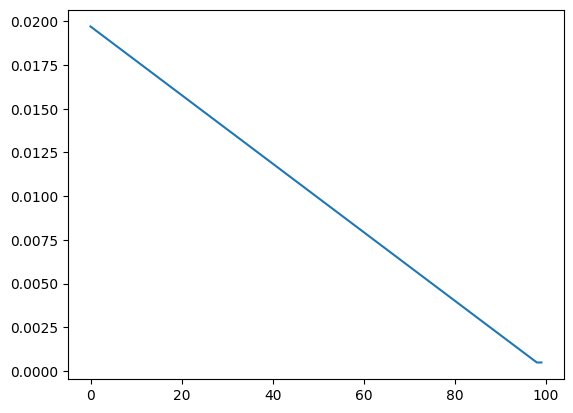

In [20]:
plt.plot(nn.softmax(update_qz(jnp.zeros(N), dp_params)))

In [23]:
results0.params["loc"]

Array([[[ 5.42576551e-01,  5.38172543e-01, -7.39764988e-01]],

       [[ 8.95489156e-01,  3.88225496e-01, -1.59962475e-01]],

       [[-1.29811072e+00, -4.54569191e-01, -2.70498323e+00]],

       [[-2.04482818e+00, -6.72746062e-01, -9.92750764e-01]],

       [[-1.00877118e+00,  2.18903854e-01, -6.08777404e-01]],

       [[ 5.29058337e-01,  5.64621389e-03, -1.64065450e-01]],

       [[ 8.54840100e-01, -1.67286530e-01, -5.15152991e-01]],

       [[ 1.17515894e-02, -4.79427189e-01, -1.20749366e+00]],

       [[ 9.11164641e-01,  1.77670014e+00, -4.67693359e-01]],

       [[ 9.93198276e-01, -8.85707438e-02,  2.48740464e-01]],

       [[-6.31523132e-01,  2.22348407e-01,  2.75457472e-01]],

       [[ 4.53839689e-01, -9.11385119e-01,  1.20738006e+00]],

       [[ 2.29325414e-01, -8.53492245e-02,  5.13699986e-02]],

       [[-7.02252984e-01, -1.05418324e-01, -1.94361365e+00]],

       [[ 9.99170244e-01,  1.38650425e-02, -1.80398810e+00]],

       [[-1.55136632e-02,  2.09643632e-01, -1.98843181e